# Diseño, implementación y validación experimental de una torreta autónoma basada en aprendizaje por refuerzo profundo y visión artificial (CV) (1 de 3)
- Este es el **primero** de 3 notebooks donde aplico técnicas de aprendizaje por refuerzo para el control de una torreta de juguete
- Los otros dos notebooks se pueden encontrar en la entrega o los enlaces a Kaggle:

2. [parte2-cnn-visionartificial](https://www.kaggle.com/code/jorgesu040/parte2-cnn-visionartificial)
3. [parte3-aplicacion-rl-cv-en-el-mundo-real](https://www.kaggle.com/code/jorgesu040/parte3-aplicacion-rl-cv-en-el-mundo-real)

Versión para GitHub de la entrega final. Instala el entorno desde el [README](../README.md).
El bloque «Probar la política guardada» ejecuta una predicción en el simulador. El entrenamiento completo es opcional.

# 1. Introducción y motivación
Recientemente he adquirido una torreta programable por control remoto ([Link aquí](https://www.crunchlabs.com/products/ir-turret)), lo que ha despertado mi interés por la integración entre software y hardware físico. Para este proyecto libre de inteligencia artificial, he decidido alejarme de los datasets estáticos clásicos (como clasificación de imágenes o texto) para abordar un problema de Reinforcement Learning (RL) aplicado a la robótica real.

Este proyecto se complementa con otro notebook de mío donde implemento detección de objetos (Computer Vision), donde uso un dataset de dianas y la CNN YOLO para proporcionarle ojos a la torreta. Sin embargo, en este notebook me centro específicamente en el "cerebro" motor: entrenar a un agente inteligente capaz de controlar una torreta física de 2 grados de libertad (Pan y Tilt) para apuntar y disparar a objetivos proyectados.

El objetivo principal es superar el desafío de pasar de una simulación a un mundo real, permitiendo a un modelo de IA interactuar con el mundo real, viendo como puede aprender física balística en un entorno simulado y ser robusta frente a las imperfecciones del mundo real (ruido de servos, latencia, gravedad).

He diseñado este entorno desde cero usando Gymnasium y varios tutoriales (Blackjack de clase junto a otros recursos online; referencias al final), modelando las físicas reales de mi hardware, incluyendo la medición experimental de la velocidad inicial del proyectil para el cálculo de la trayectoria.

![Imagen torreta en carpeta notebook-images](../docs/media/prototype.jpg)


In [ ]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

In [ ]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from gymnasium import spaces
import gymnasium as gym

seed_33 = 33

## Obtención Experimental de la Velocidad Inicial ($V_0$)
Para que la simulación física fuera realista, es necesario utilizar parámetros reales del hardware y no valores inventados. Para determinar la velocidad inicial del proyectil:

1. **Experimento:** Grabé secuencias de disparo de la torreta a diferentes distancias controladas (2 m, 2.5 m y 3 m).
2. **Análisis de Video:** Procesé las grabaciones utilizando la herramienta [Tracker Video Analysis](https://opensourcephysics.github.io/tracker-website/), y así poder rastrear la posición del proyectil frame a frame y calcular su velocidad instantánea, exportando los datos brutos a un archivo velocidad.csv.
3. **Procesamiento de Datos (Código):** El script en Python carga este dataset experimental. Dado que la velocidad inicial real ($V_0$) corresponde al momento de máxima velocidad justo tras salir del cañón (antes de que la resistencia del aire la reduzca), el código selecciona los tres valores máximos registrados en todas las mediciones y calcula su media.
4. **Valor Promedio Calculado:** Este valor promedio calculado ($\approx 14.63 \text{ m/s}$) se convierte en una constante para las ecuaciones cinemáticas del entorno simulado.


Los datos numéricos están en [velocidad.csv](../data/velocidad.csv).

In [15]:
import pandas as pd

print("--- CÁLCULO DE V0 ---")

# 1. CARGAR EL CSV
try:
    df = pd.read_csv(PROJECT_ROOT / "data" / "velocidad.csv", header=None)
    
except FileNotFoundError:
    print("No se encuentra el archivo en la ruta especificada.")
    exit()

# 2. CONSEGUIR LOS 3 VALORES MÁS ALTOS
top_3 = df[0].nlargest(3)

# 3. CALCULAR EL PROMEDIO
v0_promedio = top_3.mean()

# --- RESULTADOS ---
print(f"Los 3 valores más altos son:\n{top_3.to_string(index=False)}")
print("-" * 30)
print(f"VELOCIDAD INICIAL MEDIA (V0): {v0_promedio:.4f} m/s")
print("-" * 30)

--- CÁLCULO DE V0 ---
Los 3 valores más altos son:
14.88
14.82
14.20
------------------------------
VELOCIDAD INICIAL MEDIA (V0): 14.6333 m/s
------------------------------


# 2. Definición del espacio
- Antes de empezar a programar tenemos que definir los limites del mundo, dado que el mundo, se va a resumir en una pared de tamaño limitado y un conjunto de acciones sobre la propia torreta, podemos definir los siguentes requisitos:

    1. **Action Space**: nuestra IA, que va a controlar una torreta movida por 2 servos, puede moverse sobre si misma en los ejes X e Y, y un tercer servo que permite la disparar. Por lo tanto, nuestro espacio de acciones, será:
       - Izquierda (`leftMove`)
       - Derecha (`rightMove`)
       - Arriba (`upMove`)
       - Abajo (`downMove`)
       - Disparar (`fire`)
    2. **Observation space**: por otro lado, nuestra IA necesita saber que puede ver, para mi caso he usado una web cam Logitech C920s (1080p, 78º de vision). Entonces, podemos darle el "Error" (a qué distancia está el objetivo del centro del cañón) y definir asi nuestro error máximo (el error en X podría ir desde -960 hasta 960, y en Y desde -540 hasta 540)


Para la camara que he usado: una Logitech C920 (con un campo de visión horizontal de unos 70° y vertical de 43°):
- Horizontal: $1920 \text{ px} / 70^\circ \approx \mathbf{27} \text{ píxeles por grado}$.
- Vertical: $1080 \text{ px} / 43^\circ \approx \mathbf{25} \text{ píxeles por grado}$.
- Dado que el código Arduino mueve el Pitch 2 grados por comando, en el simulador eso equivale a: $2^\circ \times 25 \text{ px} = \mathbf{50} \text{ píxeles}$

Para la torreta, el horizonte es a los 100 grados del servo, por lo que los calculos los hacemos tomando como 100 el horizontal. 

In [ ]:
def grados_a_pixeles(yaw, pitch):
    """Convierte la orientación de la torreta en el punto donde apunta en la imagen."""
    horizonte_pitch = 100.0
    px_per_degree_yaw = 27
    px_per_degree_pitch = 25
    
    x_px = yaw * px_per_degree_yaw
    y_px = (pitch - horizonte_pitch) * px_per_degree_pitch
    return np.array([x_px, y_px], dtype=np.float32)

## Física (`simular_disparo`)
Esta función es el corazón de la simulación. Traduce los ángulos de los servos (Yaw y Pitch) a coordenadas de píxeles en la imagen, aplicando ecuaciones de cinemática clásica.

1. Calcula la distancia real a la pared usando trigonometría (al girar la torreta, la distancia a la pared plana aumenta).
2. Determina el tiempo de vuelo y la consecuente caída vertical del proyectil por la gravedad ($h = \frac{1}{2}gt^2$), usando la $V_0$ experimental.
3. Proyecta esta caída física a píxeles de la cámara usando factores de conversión hallados experimentalmente (aprox. 25 px/grado).
4. Finalmente, inyecta ruido aleatorio opcional para simular la dispersión inherente del mecanismo de disparo real.

In [ ]:
import numpy as np

# Constantes
GRAVEDAD = 9.81
V0 = v0_promedio        # Velocidad media de las mediciones (m/s)
DIST_PARED = 3.0        # Distancia a la pared (m)

# CÁMARA
PX_PER_DEG_YAW = 27.0   
PX_PER_DEG_PITCH = 25.0 
HORIZONTE_PITCH = 100.0 

def simular_disparo(yaw, pitch, ruido_std=0.0):
    """
    Calcula el impacto usando física parabólica ideal.
    Añade ruido gaussiano al final para entrenar la robustez de la IA.
    """
    # 1. GEOMETRÍA: Distancia Real
    # Al girar el Yaw, la pared se aleja trigonométricamente
    yaw_rad = np.radians(np.clip(yaw, -85, 85))
    distancia_real_m = DIST_PARED / np.cos(yaw_rad)
    
    # 2. CINEMÁTICA (Tiro Parabólico Simple)
    pitch_rel = pitch - HORIZONTE_PITCH
    pitch_rad = np.radians(pitch_rel)
    
    # Velocidad horizontal constante (sin aire)
    vx = V0 * np.cos(pitch_rad)
    if vx < 0.1: vx = 0.1
    
    # Tiempo de vuelo: t = d / v
    t = distancia_real_m / vx
    
    # Caída vertical: h = 0.5 * g * t^2
    caida_metros = 0.5 * GRAVEDAD * (t**2)
    
    # 3. PROYECCIÓN A PÍXELES
    # Calculamos dónde apunta la cámara (Mira Azul)
    x_mira = yaw * PX_PER_DEG_YAW
    y_mira = (pitch - HORIZONTE_PITCH) * PX_PER_DEG_PITCH
    
    # Calculamos cuántos píxeles baja la bala por la gravedad
    angulo_caida_rad = np.arctan(caida_metros / distancia_real_m)
    offset_caida_px = np.degrees(angulo_caida_rad) * PX_PER_DEG_PITCH
    
    # 4. COORDENADAS FINALES (Impacto Verde)
    x_final = x_mira
    y_final = y_mira - offset_caida_px 
    
    # 5. INYECCIÓN DE RUIDO 
    if ruido_std > 0:
        x_final += np.random.normal(0, ruido_std)
        y_final += np.random.normal(0, ruido_std)
        
    return np.array([x_final, y_final], dtype=np.float32)


## Diseño del Entorno (TorretaEnv)

- Para ello he creado un entorno personalizado heredando de `gym.Env` que simula la realidad física de mi hardware:

    - Espacio de Observación: Un vector continuo normalizado con el error en píxeles (X, Y) y la propia percepción de la torreta (ángulos actuales). He normalizado todo al rango [-1, 1] para facilitar la convergencia de la red neuronal.
    - Espacio de Acción: Discreto (5 acciones): Arriba, Abajo, Izquierda, Derecha y Disparar.
    - Física Balística: He implementado un modelo de tiro parabólico que calcula la caída del proyectil (h = 0.5 * g * t^2) basándose en la velocidad inicial (V_0) real medida de mi torreta.

## Estrategia de Recompensa
Uno de los mayores problemas fue evitar que el agente se quedara "quieto" para evitar penalizaciones. Para ello tras mucha prueba y error diseñé una función de recompensa que aumenta segun la cercanía al objetivo, y disminuye segun la distancia al objetivo:

1. Recompensa por Mejora: puntos positivos proporcionales a cuánto se acerca al objetivo en cada paso.
2. Castigo por Tiempo: una pequeña penalización constante (-0.05) para incentivar la rapidez y penalizar el tiempo sin hacer nada.
3. Sistema de Puntería: un sistema de "diana de dardos" para el disparo:
    - Bullseye (<30px): +1000 puntos (Gran recompensa para la precisión extrema).
    - Anillo Interior (<60px): +500 puntos.
    - Fallo: -0.5 puntos (Castigo leve para fomentar el intento de disparo).
4. A los 200 movimientos se penaliza al modelo con -50 puntos por tardar demasiado.


## Simulación de la Realidad (Ruido)
Para que el modelo sirva en el hardware real y no 'memorize' la solución, he implementado ruido en la simulación:

- Ruido de Motores: Los servos no son perfectos; al moverse, su posición real varía ligeramente respecto a la teórica.
- Dispersión de Disparo: El proyectil no siempre sale igual, se le puede añadir un ruido gaussiano para añadir desviación.


In [ ]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output


class TorretaEnv(gym.Env):
    def __init__(self):
        super(TorretaEnv, self).__init__()
        # Definiciones de límites
        self.yaw_min, self.yaw_max = -90, 90
        self.pitch_min, self.pitch_max = 33, 150
        self.horizonte_pitch = 100.0 # Cañón paralelo al suelo

        self.action_space = spaces.Discrete(5)

        # [Error_X_px, Error_Y_px, Yaw_actual, Pitch_actual]
        self.observation_space = spaces.Box(
            low=np.array([-1.0, -1.0, -1.0, -1.0], dtype=np.float32), # Valores normalizados
            high=np.array([1.0, 1.0, 1.0, 1.0], dtype=np.float32),
            dtype=np.float32
        )

        # Para la gráfica
        self.fig, self.ax = None, None

    def _get_obs(self):
        """Convierte grados/píxeles a rango -1 a 1"""
        # Calculamos el error actual
        # La cámara ve la posición real (la imprecision de los servos), no la teórica.
        puntero_pos = grados_a_pixeles(self.real_yaw, self.real_pitch)
        
        error_x = self.target_pos[0] - puntero_pos[0]
        error_y = self.target_pos[1] - puntero_pos[1]
        
        # Normalización: (Valor / Máximo)
        obs_x = np.clip(error_x / 960.0, -1.0, 1.0)
        obs_y = np.clip(error_y / 540.0, -1.0, 1.0)
        
    
        # Al modelo le pasamos los valores a los que se deberia mover el motor
        obs_yaw = np.clip(self.yaw / 90.0, -1.0, 1.0)
        
        # Para el Pitch (33 a 150), centramos en 100 y dividimos por el rango
        obs_pitch = np.clip((self.pitch - 100.0) / 60.0, -1.0, 1.0)
        
        return np.array([obs_x, obs_y, obs_yaw, obs_pitch], dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_step = 0
        
        # Iniciar los angulos
        self.yaw = 0.0
        self.pitch = self.horizonte_pitch 
        
        self.real_yaw = 0.0
        self.real_pitch = self.horizonte_pitch
        
        # Posicion del objetivo aleatoria
        self.target_pos = np.random.uniform(
                                    low=[-800, -400], 
                                    high=[800, 400], 
                                    size=(2,)).astype(np.float32)
        
        # Necesitamos saber la distancia inicial para comparar en el paso 1
        impacto_inicial = simular_disparo(self.real_yaw, self.real_pitch, ruido_std=0)
        
        # Calculamos la distancia a la pared
        self.prev_dist_impacto = np.linalg.norm(self.target_pos - impacto_inicial)
        
        # Calculo de la obsercacion inicial
        return self._get_obs(), {}
        
    def step(self, action):
        self.current_step += 1
        
        # 1. Guardado del estado previo para calcular diferencia
        prev_yaw = self.yaw
        prev_pitch = self.pitch
        
        # 2. Actualizar angulos
        move_speed = 2.0 

        # NOTA: Comentarios corregidos para lógica cartesiana (+Y Arriba)
        # Pero manteniendo lógica de servos (+Pitch -> Cañón sube -> Y imagen sube)
        if action == 0: self.pitch += move_speed   # Pitch+ (Subir Cañón)
        elif action == 1: self.pitch -= move_speed # Pitch- (Bajar Cañón)
        elif action == 2: self.yaw -= move_speed   # Left
        elif action == 3: self.yaw += move_speed   # Right

        # Clipping 
        self.yaw = np.clip(self.yaw, self.yaw_min, self.yaw_max)
        self.pitch = np.clip(self.pitch, self.pitch_min, self.pitch_max)
        
        # 3. Calculamos cuánto queríamos movernos
        delta_yaw = self.yaw - prev_yaw
        delta_pitch = self.pitch - prev_pitch
        
        # Aplicamos ruido al movimiento real, para generalizar (Solo se aplica el ruido si la torreta se mueve)
        noise_yaw = np.random.normal(0, 0.2) if delta_yaw != 0 else 0
        noise_pitch = np.random.normal(0, 0.2) if delta_pitch != 0 else 0
        
        self.real_yaw += (delta_yaw + noise_yaw)
        self.real_pitch += (delta_pitch + noise_pitch)
        
        # Clipping de los valores con ruido
        self.real_yaw = np.clip(self.real_yaw, self.yaw_min, self.yaw_max)
        self.real_pitch = np.clip(self.real_pitch, self.pitch_min, self.pitch_max)

        # Calculo de donde impactaria la bala + ruido de 5px
        impacto_real = simular_disparo(self.real_yaw, self.real_pitch, ruido_std=5.0)
        
        # 4. Distancia al objetivo
        dist_impacto = np.linalg.norm(self.target_pos - impacto_real)
        
        # 5. Recompensa (Shaping)
        # + si nos acercamos, - si nos alejamos
        dist_improvement = self.prev_dist_impacto - dist_impacto
        
        self.prev_dist_impacto = dist_impacto

        # Recompensa por acercarse: +1 punto por cada 10 pixeles de mejora
        reward = (dist_improvement / 10.0)
        
        # Coste por vivir - para que el modelo tarde menos
        reward -= 0.05
        
        # Penalización absoluta - como un embudo para a centrar
        reward -= (dist_impacto / 2000.0)
        
        
        # 6. Disparo
        terminated = False
        if action == 4:
            # A. BULLSEYE (Perfecto - <30px)
            if dist_impacto < 30: 
                reward += 1000.0 + (200 - self.current_step)
                terminated = True
                print(f"¡BULLSEYE! T:{self.current_step} Dist:{dist_impacto:.1f}px")
            
            # B. ANILLO INTERIOR (Bueno - <60px)
            elif dist_impacto < 60:
                reward += 500.0
                terminated = True # Consideramos victoria parcial
                print(f"¡DIANA! (Anillo Interior) T:{self.current_step} Dist:{dist_impacto:.1f}px")
                
            # C. FALLO
            else:
                # Penalización leve para que suela disparar y explore el acertar a la diana
                reward -= 0.5 

        # 7. Finalizar si tarda demasiado
        truncated = self.current_step >= 200
        if truncated: 
            reward -= 50 # Castigo por lento

        return self._get_obs(), float(reward), terminated, truncated, {}
    

    def render(self):
        import matplotlib.pyplot as plt
        from IPython.display import display, clear_output
        
        # 1. Configuración de la Ventana (Solo la primera vez)
        if self.fig is None:
            self.fig, self.ax = plt.subplots(figsize=(10, 6))
        
        self.ax.clear()
        
        # A. EL OBJETIVO (ROJO)
        self.ax.scatter(self.target_pos[0], self.target_pos[1], 
                        c='red', s=300, marker='o', label='Objetivo Real')
        
        
        # B. LA MIRA (AZUL) -> REALIDAD CON RUIDO
        # Queremos ver lo que ve la cámara (Realidad Ruidosa)
        mira_pos = grados_a_pixeles(self.real_yaw, self.real_pitch)
        self.ax.scatter(mira_pos[0], mira_pos[1], 
                        c='blue', s=200, marker='+', label='Mira (Cámara)')
        
        # C. EL IMPACTO (VERDE) 
        # FIX: Usamos la función maestra para ser consistentes con step
        impacto_pos = simular_disparo(self.real_yaw, self.real_pitch, ruido_std=5)
        
        self.ax.scatter(impacto_pos[0], impacto_pos[1], 
                        c='green', s=150, marker='x', label='Impacto Real')
        
        # DIBUJAR LA FLECHA DE GRAVEDAD 
        self.ax.annotate('', xy=(impacto_pos[0], impacto_pos[1]), xytext=(mira_pos[0], mira_pos[1]),
                         arrowprops=dict(arrowstyle='->', color='gray', linestyle='--'))
        

        # D. INFORMACIÓN Y ESTÉTICA
        dist_error = np.linalg.norm(self.target_pos - impacto_pos)
        
        self.ax.set_xlim(-960, 960)
        self.ax.set_ylim(-540, 540) 
        self.ax.axhline(0, color='black', alpha=0.3)
        self.ax.axvline(0, color='black', alpha=0.3)
        self.ax.grid(True, linestyle=':', alpha=0.6)
        
        self.ax.legend(loc='upper right')
        
        # Cálculo solo para mostrar en título (informativo)
        caida_visual = impacto_pos[1] - mira_pos[1]

        self.ax.set_title(f"STEP: {self.current_step} | Yaw Real: {self.real_yaw:.1f}º (Creencia: {self.yaw:.1f}º)\n"
                          f"Caída Vertical: {caida_visual:.1f}px | Error Impacto: {dist_error:.1f}px")
        
        # Mostrar
        display(self.fig)
        clear_output(wait=True)

## Inicialización y wrappers del Entorno
Se instancia el entorno personalizado TorretaEnv y se le aplican Wrappers (envoltorios) para capturar métricas clave (duración del episodio, recompensa acumulada) al final de cada partida.

- RecordEpisodeStatistics: Captura métricas clave (duración del episodio, recompensa acumulada) al final de cada partida.
- Monitor: Registra estos datos en archivos de log en ./logs/, permitiendo visualizar posteriormente la curvas de aprendizaje.

### Probar la política guardada

El repositorio incluye el checkpoint DQN de la entrega. Carga la política y prueba un paso del entorno sin conectar la torreta.

In [ ]:
from stable_baselines3 import DQN

demo_env = TorretaEnv()
demo_policy = DQN.load(PROJECT_ROOT / "models" / "dqn-policy.zip", device="cpu")
observation, _ = demo_env.reset()
action, _ = demo_policy.predict(observation, deterministic=True)
_, reward, terminated, truncated, _ = demo_env.step(int(action.item()))
print(f"Acción: {action.item()} · recompensa: {reward:.2f}")

In [ ]:
import os
import gymnasium as gym
from stable_baselines3.common.monitor import Monitor
from gymnasium.wrappers import RecordEpisodeStatistics 

# 1. Creamos el entorno
env = TorretaEnv()

# 2. Envolvemos para estadísticas (como en el notebook de Blackjack)
env = RecordEpisodeStatistics(env)

# 3. Monitor de Stable Baselines para el log del entrenamiento
log_dir = PROJECT_ROOT / "runs" / "rl" / "train"
os.makedirs(log_dir, exist_ok=True)
env = Monitor(env, str(log_dir / "monitor.csv"))

print("Entorno configurado con éxito")

## Algoritmo usado
Para ello me he basado en el ejemplo del Blackjack de Clase:
- He usado DQN (Deep Q-Network) de la librería Stable-Baselines3 con una política de Perceptrón Multicapa (MlpPolicy). Ajusté la tasa de aprendizaje (learning_rate=0.00005) para evitar el "olvido" que observé en pruebas iniciales donde el agente aprendía y luego desaprendía repentinamente.

In [ ]:
from stable_baselines3 import DQN

# Configura el cerebro de la IA
model = DQN(
    policy="MlpPolicy",
    env=env,
    learning_rate=0.00005, # Velocidad de aprendizaje
    buffer_size=50000,   # Memoria de partidas pasadas
    learning_starts=1000, # Pasos antes de empezar a aprender (solo observa al principio)
    batch_size=64,
    gamma=0.99,          # Factor de descuento (importancia de recompensas futuras)
    exploration_fraction=0.4, # El 40% del tiempo estará probando cosas locas
    verbose=1            # Para que nos enseñe el progreso por pantalla
)

# 3. Entrenamiento con Callbacks
Una vez configurado el entrenamiento del modelo durante 100,000 pasos, he añadido un callback para evaluar el agente y guardar el mejor modelo usando el Callback de Evaluación. En lugar de quedarse con la última versión de la IA (que a veces "desaprende" o explora demasiado al final), este callback pausa el entrenamiento cada 500 pasos, prueba al agente en 5 partidas de examen y guarda una copia de seguridad solo si ha superado su récord anterior. Al terminar, cargo ese best_model, asegurándome de usar la versión más obtiene mejores recompensas y no la última.

In [ ]:
from stable_baselines3.common.callbacks import EvalCallback

# Callback
# Cada 500 pasos evalúa 5 partidas. Si es el mejor hasta ahora, lo guarda en 'best_model'.
eval_callback = EvalCallback(env, 
                             best_model_save_path=str(log_dir),
                             log_path=str(log_dir), 
                             eval_freq=500,
                             deterministic=True, 
                             render=False)

model.learn(total_timesteps=100000, callback=eval_callback, progress_bar=True)

# Cargar el mejor modelo, no el último
model = DQN.load(log_dir / "best_model.zip", device="cpu")


# 4. Resultados y Análisis


## Convergencia del Entrenamiento
Como se observa en las gráficas de entrenamiento, el modelo comienza con un comportamiento aleatorio (recompensas negativas) y converge progresivamente hacia recompensas positivas, estabilizándose alrededor del episodio ~800.

Como se puede el agente aprendió primero a no disparar al azar (reduciendo castigos drásticos) y posteriormente a perseguir el objetivo a la vez que ser más eficiente y dar menos pasos.


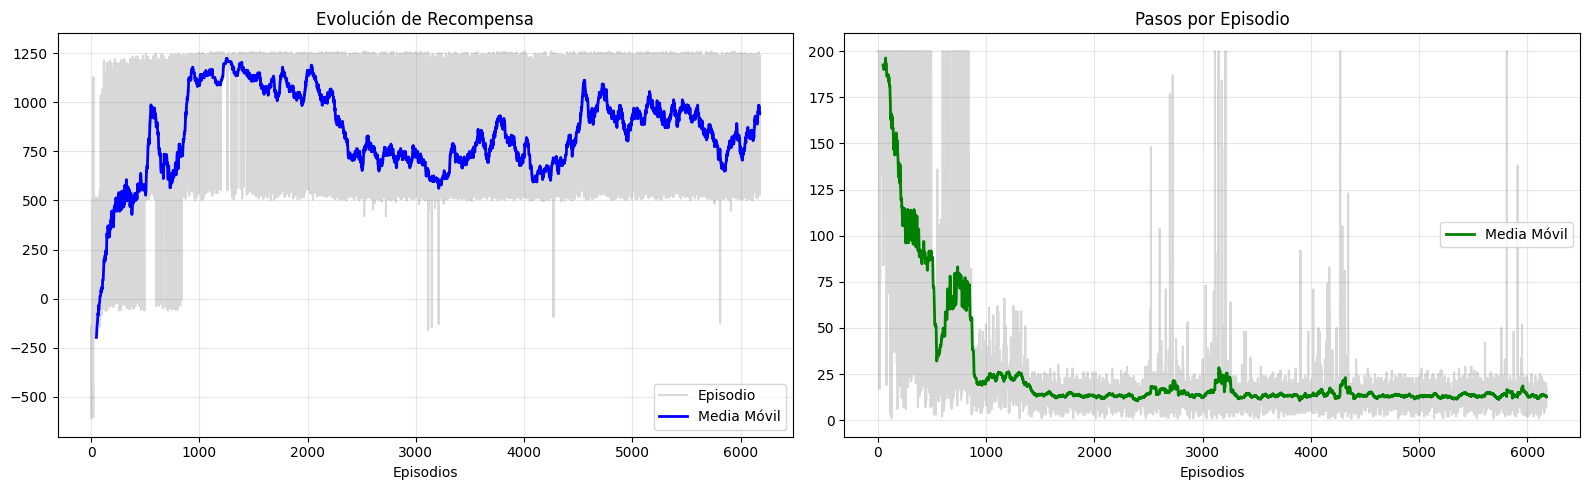

In [22]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import glob
import os

def plot_training_results(log_folder=log_dir):
    """
    Busca 'monitor.csv' o cualquier '*.csv'. y crea las gráficas del entrenamiento
    """
    # Buscamos específicamente monitor.csv o cualquier csv
    monitor_files = glob.glob(os.path.join(log_folder, "monitor.csv"))
    # Si no encuentra 'monitor.csv', buscamos cualquier cosa que acabe en .csv
    if not monitor_files:
        monitor_files = glob.glob(os.path.join(log_folder, "*.csv"))

    if len(monitor_files) > 0:
        try:
            df = pd.read_csv(monitor_files[0], skiprows=1)
        except:
            df = pd.read_csv(monitor_files[0], skiprows=2)
        

        # Calculamos media móvil
        window = 50 
        rew_ma = df['r'].rolling(window=window).mean()
        len_ma = df['l'].rolling(window=window).mean()
        
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
        
        # Gráfica 1: Recompensa
        ax1.plot(df.index, df['r'], alpha=0.3, color='gray', label='Episodio')
        ax1.plot(df.index, rew_ma, color='blue', linewidth=2, label='Media Móvil')
        ax1.set_title("Evolución de Recompensa")
        ax1.set_xlabel("Episodios")
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        # Gráfica 2: Velocidad
        ax2.plot(df.index, df['l'], alpha=0.3, color='gray')
        ax2.plot(df.index, len_ma, color='green', linewidth=2, label='Media Móvil')
        ax2.set_title("Pasos por Episodio")
        ax2.set_xlabel("Episodios")
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    else:
        print("CSV no encontrado")

# Ejecutar
plot_training_results()

## Comportamiento aprendido

- Como se puede ver en mapa de estrategia generado, hay una clara frontera de decisión diagonal, lo que indica que el agente ha interiorizado la corrección de errores en ambos ejes simultáneamente.
- Un resultado muy chulo es que el agente ha aprendido  a apuntar ligeramente por encima del objetivo si se entrena a mayor distancia de la pared. Esto no fue programado explícitamente, ya que no lo recibe en sus observaciones, sino que el agente "descubrió" la gravedad: para maximizar la recompensa del disparo, debía compensar la caída balística que la simulación imponía.

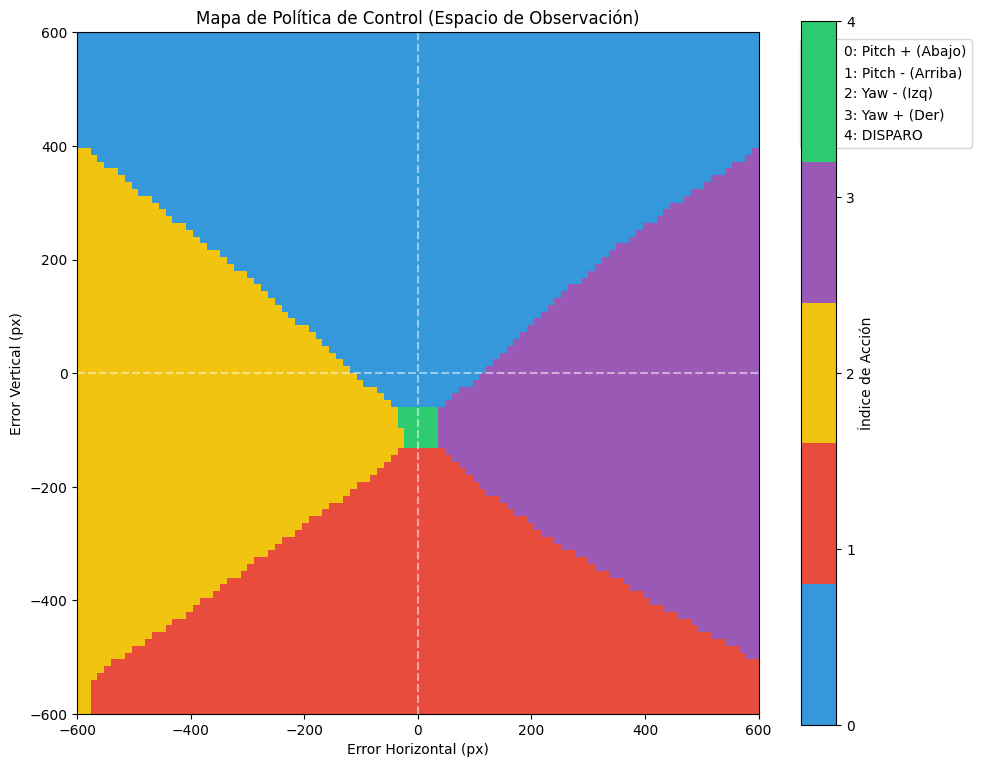

In [23]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
import numpy as np
from stable_baselines3 import DQN

# Carga del modelo
checkpoint = log_dir / "best_model.zip"
if not checkpoint.is_file():
    checkpoint = PROJECT_ROOT / "models" / "dqn-policy.zip"
best_model = DQN.load(checkpoint, device="cpu")

def plot_turret_policy(model, resolution=100, range_pix=600):
    """
    Visualiza la política de decisión del agente mapeando acciones sobre el espacio de estados.
    
    Args:
        model: Modelo RL entrenado (Stable Baselines3).
        resolution (int): Resolución de la malla de puntos.
        range_pix (int): Rango en píxeles a evaluar desde el centro.
    """
    print(f"Generando mapa de calor de política ({resolution}x{resolution})...")
    
    xs = np.linspace(-range_pix, range_pix, resolution)
    ys = np.linspace(-range_pix, range_pix, resolution) 
    
    action_map = np.zeros((resolution, resolution))
    
    for i, y in enumerate(ys):
        for j, x in enumerate(xs):
            # Normalización basada en las dimensiones del entorno (960x540)
            obs_x = np.clip(x / 960.0, -1.0, 1.0)
            obs_y = np.clip(y / 540.0, -1.0, 1.0)
            
            # Construcción del vector de observación: [Error_X, Error_Y, Yaw, Pitch]
            # Se asumen ángulos neutrales (0.0) para visualizar la respuesta al error posicional
            obs = np.array([obs_x, obs_y, 0.0, 0.0], dtype=np.float32)
            
            # Inferencia determinista
            action, _ = model.predict(obs, deterministic=True)
            action_map[i, j] = int(action.item())

    # Configuración de visualización
    # 0: Pitch+, 1: Pitch-, 2: Yaw-, 3: Yaw+, 4: Disparo
    colors = ['#3498db', '#e74c3c', '#f1c40f', '#9b59b6', '#2ecc71'] 
    labels = ['Pitch + (Abajo)', 'Pitch - (Arriba)', 'Yaw - (Izq)', 'Yaw + (Der)', 'DISPARO']
    cmap = ListedColormap(colors)
    
    plt.figure(figsize=(10, 8))
    
    # Renderizado del mapa
    plt.imshow(action_map, extent=[-range_pix, range_pix, -range_pix, range_pix], 
               origin='lower', cmap=cmap, vmin=0, vmax=4)
    
    plt.colorbar(ticks=[0, 1, 2, 3, 4], label='Índice de Acción')
    plt.title("Mapa de Política de Control (Espacio de Observación)")
    plt.xlabel("Error Horizontal (px)")
    plt.ylabel("Error Vertical (px)")
    
    # Leyenda
    patches = [mpatches.Patch(color=colors[i], label=f"{i}: {labels[i]}") for i in range(5)]
    plt.legend(handles=patches, bbox_to_anchor=(1.05, 1), loc='upper left')
    
    # Referencias centrales
    plt.axhline(0, color='white', alpha=0.5, linestyle='--')
    plt.axvline(0, color='white', alpha=0.5, linestyle='--')
    plt.tight_layout()
    plt.show()

# Ejecución
if 'best_model' in locals():
    plot_turret_policy(best_model)

## Test Visual del Modelo (render)
Una vez entrenado el agente, este bloque ejecuta una simulación en tiempo real para ver cómo se comporta.

1. Carga el mejor modelo guardado (DQN.load).
2. Entra en un bucle while donde la IA predice la siguiente acción basándose en lo que "ve" (obs).
3. Lo más importante es la llamada a env.render(), que dibuja frame a frame la posición del objetivo, la mira de la torreta y el punto de impacto calculado, permitiéndome verificar visualmente si la IA realmente ha aprendido a compensar la gravedad o si está disparando al azar.

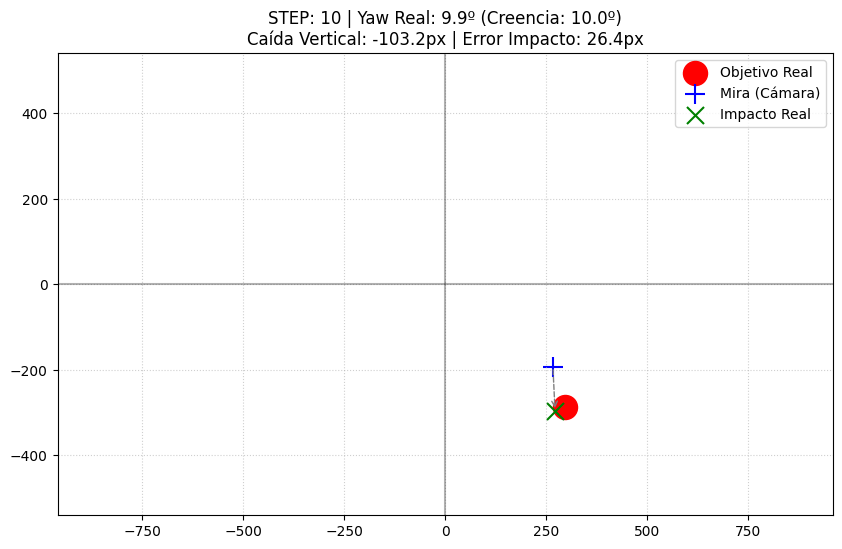

In [24]:
import time
import matplotlib.pyplot as plt

# Recargar modelo
model = best_model 

# Reiniciar entorno
env = TorretaEnv() 

obs, info = env.reset()
done = False

print("INICIANDO SIMULACIÓN GRÁFICA...")
time.sleep(1)

while not done:
    action, _ = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = env.step(action)
    
    # El metodo render se encarga de mostrar lo que esta haciendo el modelo y donde caería la bala
    env.render()
    
    # Velocidad de la animación
    time.sleep(0.09)
    
    done = terminated or truncated

if terminated:
    print("¡DIANA!")
else:
    print("TIEMPO")

# 5. Conclusiones y Referencias
Este proyecto ha demostrado que es posible entrenar un agente de RL robusto con un simulador físico simplificado. La principal lección ha sido la importancia de la definicion de las recompensas: pequeñas variaciones en los castigos cambiaban totalmente la personalidad del agente (de "cobarde" a "imprudente").

Posibles mejoras futuras:

- Si hubiera tenido más tiempo, me gustaría probar a enseñarle al agente a entender la profundiad con objetivos a diferentes distancias.
- Tambien, si mis conocimientos de física fueran más sólidos, podría probar a implementar un modelo físico más realista.

Fuentes:

- Documentación oficial de Gymnasium y Stable-Baselines3. (https://gymnasium.farama.org/)
- Los notebooks de clase (El Bandido de 10 Brazos) y el de DQN con Blackjack.
- Un tutorial online sobre blackjack y gymnasium. (https://colab.research.google.com/drive/1FcmLvSHD8UviETonbESG65fxZUKMBcza#scrollTo=3aNuuDy9mr7S)
